In [33]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.tree import export_text
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_squared_error
import xgboost as xgb

In [2]:
df = pd.read_csv('car_fuel_efficiency_2026.csv')
df.tail(10)

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
9990,1975,Asia,Diesel,Front-wheel drive,4,1940,6,236.0,3630,19.7,32.4
9991,1987,USA,Gasoline,Rear-wheel drive,4,2130,5,228.0,4040,17.2,26.3
9992,2000,Europe,Gasoline,Front-wheel drive,3,2470,7,271.0,3990,17.3,28.1
9993,2007,USA,Diesel,Rear-wheel drive,2,1950,6,234.0,4250,19.9,30.7
9994,1993,Asia,Gasoline,Rear-wheel drive,2,2360,6,257.0,4610,22.2,30.1
9995,2005,USA,Gasoline,All-wheel drive,4,2470,6,271.0,4690,18.9,27.4
9996,1993,Asia,Gasoline,All-wheel drive,2,2300,6,244.0,4370,19.0,30.0
9997,2014,USA,Gasoline,All-wheel drive,3,2480,6,267.0,4590,18.4,28.1
9998,2004,USA,Hybrid,Rear-wheel drive,5,2180,6,270.0,4450,20.9,32.2
9999,2011,USA,Diesel,Front-wheel drive,4,2380,6,295.0,4370,17.6,30.2


In [3]:
df = df.fillna(0)

In [4]:
df.isnull().sum()

model_year             0
origin                 0
fuel_type              0
drivetrain             0
num_doors              0
engine_displacement    0
num_cylinders          0
horsepower             0
vehicle_weight         0
acceleration           0
fuel_efficiency_mpg    0
dtype: int64

In [5]:
df.dtypes

model_year               int64
origin                     str
fuel_type                  str
drivetrain                 str
num_doors                int64
engine_displacement      int64
num_cylinders            int64
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

In [6]:
df.nunique()

model_year              50
origin                   3
fuel_type                3
drivetrain               3
num_doors                4
engine_displacement    127
num_cylinders            5
horsepower             154
vehicle_weight         176
acceleration            94
fuel_efficiency_mpg    188
dtype: int64

In [7]:
df.num_doors.value_counts()

num_doors
4    3417
3    3301
2    1647
5    1635
Name: count, dtype: int64

In [8]:
df.num_cylinders.value_counts()

num_cylinders
6    7080
7    1622
5    1286
8      10
4       2
Name: count, dtype: int64

In [9]:
df.num_doors = df.num_doors.astype(str)
df.num_cylinders = df.num_cylinders.astype(str)

In [10]:
df.dtypes

model_year               int64
origin                     str
fuel_type                  str
drivetrain                 str
num_doors                  str
engine_displacement      int64
num_cylinders              str
horsepower             float64
vehicle_weight           int64
acceleration           float64
fuel_efficiency_mpg    float64
dtype: object

In [12]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
y_train = df_train['fuel_efficiency_mpg']
y_val = df_val['fuel_efficiency_mpg']
y_test = df_test['fuel_efficiency_mpg']

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [13]:
dv = DictVectorizer(sparse=True)
train_dict = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)

test_dict = df_test.to_dict(orient='records')
X_test = dv.transform(test_dict)

# Q1

In [14]:
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)
print(export_text(dt, feature_names=list(dv.get_feature_names_out())))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



'model_year' is used for splitting the data when max_depth = 1

# Q2

In [17]:
rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)
pred = rf.predict(X_val)
rmse = root_mean_squared_error(y_val, pred)
print(rmse)

1.84675034858532


# Q3

In [20]:
n = [10, 50, 100, 150]
rmse = []
for val in n:
    rf = RandomForestRegressor(n_estimators=val, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)
    pred = rf.predict(X_val)
    rmse.append(root_mean_squared_error(y_val, pred))
min_rmse = rmse.index(min(rmse))
print(f'The value that gives the lowest validation RMSE is {n[min_rmse]}')

The value that gives the lowest validation RMSE is 150


# Q4

In [21]:
m = [10, 15, 20, 25]
rmse_mean = []
for num in m:
    rmse = []
    n = [10, 50, 100, 150]
    for val in n:
        rf = RandomForestRegressor(n_estimators=val, random_state=1, n_jobs=-1, max_depth=num)
        rf.fit(X_train, y_train)
        pred = rf.predict(X_val)
        rmse.append(root_mean_squared_error(y_val, pred))
    rmse_mean.append(np.mean(rmse))
min_rmse = rmse_mean.index(min(rmse_mean))
print(f'The best max_depth value is {m[min_rmse]}')

The best max_depth value is 10


# Q5

In [32]:
rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1, max_depth=20)
rf.fit(X_train, y_train)
feature_names = dv.get_feature_names_out()

feat_importance = rf.feature_importances_

df_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': feat_importance
}).sort_values(by='importance', ascending=False)
df_importance.head()

,feature,importance
9,model_year,0.293919
22,vehicle_weight,0.203364
6,fuel_type=Gasoline,0.160710
8,horsepower,0.077156
4,engine_displacement,0.059793


# Q6

In [44]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [45]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))

    columns = ['num_iter', 'train_rmse', 'val_rmse']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

In [46]:
scores = {}

In [47]:
%%capture output
watchlist = [(dtrain, 'train'), (dval, 'val')]
xgb_params = {
    'eta': 0.3, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}
model = xgb.train(xgb_params, dtrain, num_boost_round=100, evals=watchlist)

In [48]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.3'

In [49]:
%%capture output
watchlist = [(dtrain, 'train'), (dval, 'val')]
xgb_params = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}
model = xgb.train(xgb_params, dtrain, num_boost_round=100, evals=watchlist)

In [57]:
key = 'eta=%s' % (xgb_params['eta'])
scores[key] = parse_xgb_output(output)
key

'eta=0.1'

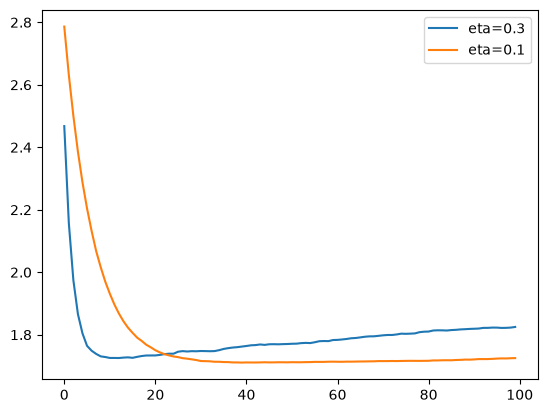

In [56]:
for key, df_score in scores.items():
    plt.plot(df_score.num_iter, df_score.val_rmse, label=key)

plt.legend()